[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/lectures/05_regularization.ipynb)

# Lecture 5 — Generalisation and Regularisation

**Neural Networks · Master's course**

Minimising the training loss is only a means to an end. What we care about is
the loss on **new** data drawn from the same distribution — the *generalisation*
error. A network with enough parameters can drive its training loss to zero on
almost any dataset, including one with random labels (Zhang et al., 2017), so
a small training loss by itself tells us very little.

**Regularisation** is any modification of the learning procedure that is
intended to reduce the generalisation error, possibly at the expense of the
training error. In this lecture we

1. revisit under- and overfitting and the **bias–variance** decomposition,
2. watch a wide MLP overfit a small, noisy dataset,
3. study the classical regularisers for neural networks — **weight decay**,
   **early stopping**, **dropout** and **data augmentation**,
4. look at **batch normalisation** (and layer normalisation), which mainly speeds
   up optimisation but also has a regularising side effect, and
5. end with a modern twist: **double descent**.

In [1]:
import copy

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.manual_seed(0)
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (5, 4)
plt.rcParams["axes.grid"] = True
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## 1. Under- and overfitting

Let the data be generated as $y = f(x) + \varepsilon$ with
$\mathbb E[\varepsilon]=0$, $\operatorname{Var}[\varepsilon]=\sigma^2$, and let
$\hat f_{\mathcal D}$ be the model fitted on a random training set $\mathcal D$.
For a fixed test input $x$, the expected squared error over training sets and noise
decomposes as

$$\mathbb E_{\mathcal D,\varepsilon}\big[(y - \hat f_{\mathcal D}(x))^2\big]
= \underbrace{\big(f(x) - \bar f(x)\big)^2}_{\text{bias}^2}
+ \underbrace{\mathbb E_{\mathcal D}\big[(\hat f_{\mathcal D}(x) - \bar f(x))^2\big]}_{\text{variance}}
+ \underbrace{\sigma^2}_{\text{irreducible noise}},
\qquad \bar f(x) = \mathbb E_{\mathcal D}[\hat f_{\mathcal D}(x)].$$

*Proof sketch:* write $y - \hat f = (f - \bar f) + (\bar f - \hat f) + \varepsilon$,
square, and take expectations; all cross terms vanish because
$\mathbb E[\varepsilon]=0$, $\varepsilon$ is independent of $\mathcal D$, and
$\mathbb E_{\mathcal D}[\bar f - \hat f_{\mathcal D}] = 0$.

A model that is too simple has high **bias** (it underfits: both training and
test errors are high); a model that is too flexible for the amount of data has
high **variance** (it overfits: it fits the noise of its particular training set,
training error is low, test error high). The classic illustration is polynomial
regression on 20 noisy samples of $\sin(2\pi x)$.

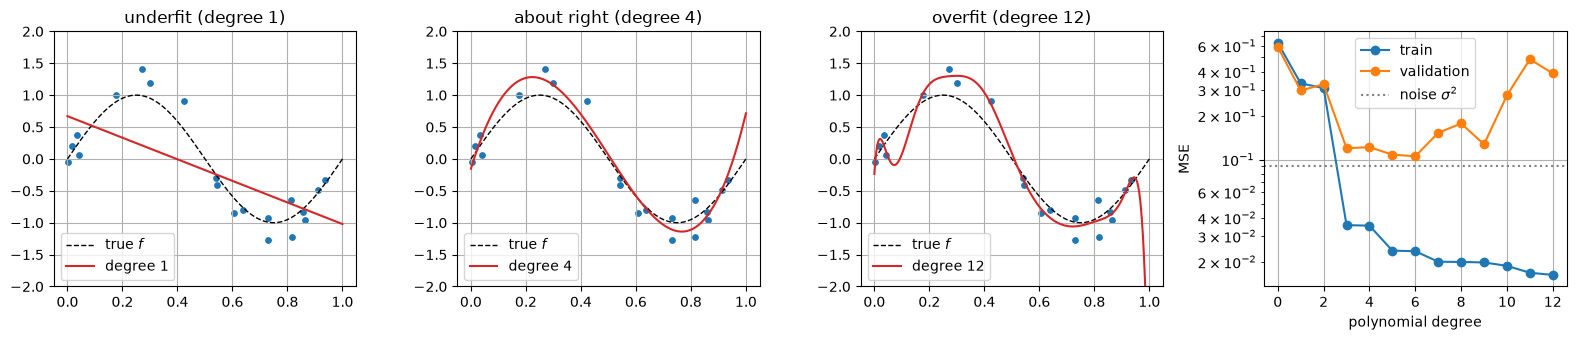

In [2]:
f_true = lambda x: np.sin(2 * np.pi * x)

def sample(n, noise=0.3, r=rng):
    x = r.uniform(0, 1, n)
    return x, f_true(x) + noise * r.standard_normal(n)

def design(x, degree):
    return np.vander(2 * x - 1, degree + 1, increasing=True)   # 1, x, x^2, ... on [-1, 1]

def fit_poly(x, y, degree):
    return np.linalg.lstsq(design(x, degree), y, rcond=None)[0]

x_tr, y_tr = sample(20)
x_va, y_va = sample(500)
degrees = list(range(13))
tr_err, va_err = [], []
for d in degrees:
    w = fit_poly(x_tr, y_tr, d)
    tr_err.append(np.mean((design(x_tr, d) @ w - y_tr) ** 2))
    va_err.append(np.mean((design(x_va, d) @ w - y_va) ** 2))

xg = np.linspace(0, 1, 300)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, d, title in zip(axes[:3], [1, 4, 12], ["underfit", "about right", "overfit"]):
    ax.scatter(x_tr, y_tr, s=15, color="C0")
    ax.plot(xg, f_true(xg), "k--", lw=1, label="true $f$")
    ax.plot(xg, design(xg, d) @ fit_poly(x_tr, y_tr, d), "C3", label=f"degree {d}")
    ax.set_ylim(-2, 2); ax.legend(loc="lower left"); ax.set_title(f"{title} (degree {d})")
axes[3].semilogy(degrees, tr_err, "o-", label="train")
axes[3].semilogy(degrees, va_err, "o-", label="validation")
axes[3].axhline(0.3 ** 2, color="gray", ls=":", label="noise $\\sigma^2$")
axes[3].set_xlabel("polynomial degree"); axes[3].set_ylabel("MSE"); axes[3].legend()
plt.tight_layout(); plt.show()

We can estimate the bias and variance directly by refitting on many independent
training sets and looking at the spread of the fitted curves.

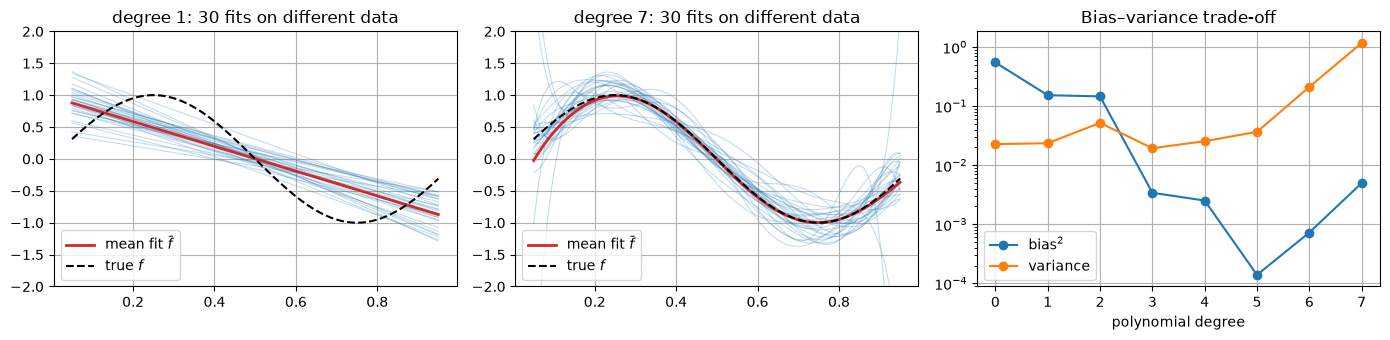

In [3]:
def bias_variance(degree, n_sets=200, n=25):
    r = np.random.default_rng(1)
    xs = np.linspace(0.05, 0.95, 100)
    preds = np.array([design(xs, degree) @ fit_poly(*sample(n, r=r), degree) for _ in range(n_sets)])
    bias2 = np.mean((preds.mean(0) - f_true(xs)) ** 2)
    var = np.mean(preds.var(0))
    return bias2, var, xs, preds

degs = list(range(8))
bv = [bias_variance(d)[:2] for d in degs]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, d in zip(axes[:2], [1, 7]):
    _, _, xs, preds = bias_variance(d)
    for p in preds[:30]:
        ax.plot(xs, p, color="C0", alpha=0.25, lw=0.8)
    ax.plot(xs, preds.mean(0), "C3", lw=2, label="mean fit $\\bar f$")
    ax.plot(xs, f_true(xs), "k--", label="true $f$")
    ax.set_ylim(-2, 2); ax.set_title(f"degree {d}: 30 fits on different data"); ax.legend(loc="lower left")
axes[2].semilogy(degs, [b for b, _ in bv], "o-", label="bias$^2$")
axes[2].semilogy(degs, [v for _, v in bv], "o-", label="variance")
axes[2].set_xlabel("polynomial degree"); axes[2].legend(); axes[2].set_title("Bias–variance trade-off")
plt.tight_layout(); plt.show()

Increasing capacity trades bias for variance. Regularisation gives us a
*continuous* knob for this trade-off that does not require changing the
architecture: we keep a flexible model but restrict, in a soft way, which
functions it can easily reach.

## 2. A neural network that overfits

To see overfitting in a neural network on a small budget, we deliberately make
the problem hard: train on only **300** digit images, of which **20 %** have a
random (wrong) label, with a wide MLP ($64\to256\to256\to10$, about 85 000
parameters — almost 300 parameters per training example). The validation and
test sets are clean.

In [4]:
digits = load_digits()
X_all = (digits.data / 16.0).astype(np.float32)
y_all = digits.target.astype(np.int64)
X_pool, X_test, y_pool, y_test = train_test_split(X_all, y_all, test_size=0.25, random_state=0, stratify=y_all)
X_rest, X_val, y_rest, y_val = train_test_split(X_pool, y_pool, test_size=0.3, random_state=0, stratify=y_pool)

N_TRAIN, NOISE = 300, 0.2
X_small = X_rest[:N_TRAIN]
y_small = y_rest[:N_TRAIN].copy()
flip = rng.random(N_TRAIN) < NOISE
y_small[flip] = rng.integers(0, 10, flip.sum())       # some of them are (by chance) correct again
print(f"train {len(X_small)} (wrong labels: {np.mean(y_small != y_rest[:N_TRAIN]):.0%}) | "
      f"val {len(X_val)} | test {len(X_test)}")

to_t = lambda X, y: TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
train_ds, val_ds, test_ds = to_t(X_small, y_small), to_t(X_val, y_val), to_t(X_test, y_test)
val_loader = DataLoader(val_ds, batch_size=512)
test_loader = DataLoader(test_ds, batch_size=512)

train 300 (wrong labels: 20%) | val 405 | test 450


We use the training loop from Lecture 4, packaged as `train_model`. It records,
after every epoch, the loss and accuracy on the (noisy) training set and on the
validation set — always evaluated in `eval` mode.

In [5]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return total / n, correct / n


def train_model(model, optimizer, train_ds, n_epochs=120, batch_size=32, seed=0, verbose=False):
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g)
    train_eval_loader = DataLoader(train_ds, batch_size=512)
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc")}
    for epoch in range(n_epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        for prefix, ldr in (("train", train_eval_loader), ("val", val_loader)):
            l, a = evaluate(model, ldr)
            hist[prefix + "_loss"].append(l); hist[prefix + "_acc"].append(a)
        if verbose and (epoch + 1) % 20 == 0:
            print(f"epoch {epoch + 1:3d} | train loss {hist['train_loss'][-1]:.3f} acc {hist['train_acc'][-1]:.3f} "
                  f"| val loss {hist['val_loss'][-1]:.3f} acc {hist['val_acc'][-1]:.3f}")
    return hist


def make_mlp(hidden=256, dropout=0.0):
    layers = [nn.Linear(64, hidden), nn.ReLU()]
    if dropout > 0:
        layers.append(nn.Dropout(dropout))
    layers += [nn.Linear(hidden, hidden), nn.ReLU()]
    if dropout > 0:
        layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(hidden, 10))
    return nn.Sequential(*layers).to(device)


def plot_history(hists, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for i, (name, h) in enumerate(hists.items()):
        axes[0].plot(h["train_loss"], color=f"C{i}", ls="--")
        axes[0].plot(h["val_loss"], color=f"C{i}", label=name)
        axes[1].plot(h["train_acc"], color=f"C{i}", ls="--")
        axes[1].plot(h["val_acc"], color=f"C{i}", label=name)
    axes[0].set_ylabel("cross-entropy"); axes[1].set_ylabel("accuracy")
    for ax in axes:
        ax.set_xlabel("epoch"); ax.legend()
    axes[0].set_title("loss (dashed: train, solid: validation)"); axes[1].set_title("accuracy")
    fig.suptitle(title); plt.tight_layout(); plt.show()

parameters: 85002


epoch  20 | train loss 0.699 acc 0.803 | val loss 0.542 acc 0.859
epoch  40 | train loss 0.379 acc 0.893 | val loss 0.573 acc 0.835


epoch  60 | train loss 0.174 acc 0.960 | val loss 0.706 acc 0.785
epoch  80 | train loss 0.077 acc 0.993 | val loss 0.837 acc 0.763


epoch 100 | train loss 0.035 acc 1.000 | val loss 0.947 acc 0.758
epoch 120 | train loss 0.018 acc 1.000 | val loss 1.036 acc 0.751


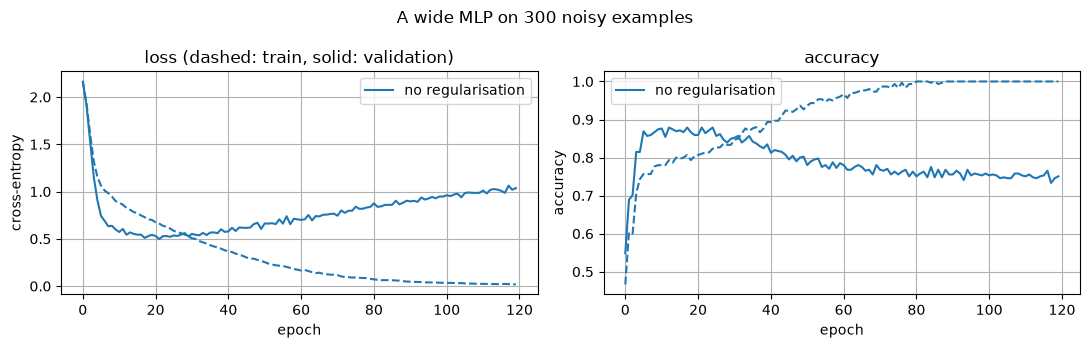

In [6]:
torch.manual_seed(0)
baseline = make_mlp()
print("parameters:", sum(p.numel() for p in baseline.parameters()))
hist_base = train_model(baseline, torch.optim.Adam(baseline.parameters(), lr=1e-3), train_ds, verbose=True)
plot_history({"no regularisation": hist_base}, "A wide MLP on 300 noisy examples")

The textbook picture of overfitting:

* the **training** accuracy climbs to 100 % — the network memorises the wrong
  labels too;
* the **validation** loss reaches its minimum early (after roughly 20 epochs) and then
  *increases*, while the validation accuracy slowly drops.

Note that the validation *loss* deteriorates much more than the validation
*accuracy*: the network becomes over-confident, and cross-entropy punishes
confident mistakes heavily.

## 3. Weight decay ($L_2$ regularisation)

Add a penalty on the size of the weights to the loss:

$$\tilde{\mathcal L}(\theta) = \mathcal L(\theta) + \frac{\lambda}{2}\lVert \mathbf w\rVert_2^2,
\qquad \nabla\tilde{\mathcal L} = \nabla\mathcal L + \lambda\mathbf w .$$

A gradient-descent step then reads

$$\mathbf w \leftarrow \mathbf w - \eta(\nabla\mathcal L + \lambda\mathbf w)
= (1 - \eta\lambda)\,\mathbf w - \eta\nabla\mathcal L ,$$

i.e. the weights are multiplicatively **decayed** towards zero at every step —
hence the name. Interpretations:

* **Bayesian:** minimising $\tilde{\mathcal L}$ is MAP estimation with a Gaussian
  prior $\mathbf w\sim\mathcal N(0, \lambda^{-1} I)$ (for a loss that is a negative
  log-likelihood summed over the data; with a mean loss, $\lambda$ is rescaled by $N$).
* **Smoothness:** for a network, small weights mean a small Lipschitz constant —
  the function cannot change abruptly between nearby inputs.
* **Linear regression** (ridge): along each eigen-direction of $X^\top X$ with
  eigenvalue $s_j$, the solution is shrunk by the factor $s_j/(s_j+\lambda)$;
  directions that the data barely constrain are suppressed most.

Biases are usually not decayed: they do not contribute to the sensitivity to
the input, and penalising them can cause underfitting.

### Adam + $L_2$ versus AdamW

For plain SGD, "add $\lambda\mathbf w$ to the gradient" and "decay the weights by
$(1-\eta\lambda)$" are the same thing. For adaptive methods they are **not**:
in Adam the gradient (including $\lambda\mathbf w$) is divided by
$\sqrt{\hat v_t}$, so weights with large historical gradients are decayed
*less*. Loshchilov & Hutter (2019) proposed **decoupled weight decay** (AdamW):

$$\mathbf w \leftarrow \mathbf w - \eta\Big(\frac{\hat{\mathbf m}_t}{\sqrt{\hat{\mathbf v}_t}+\epsilon} + \lambda\mathbf w\Big),$$

where $\hat{\mathbf m}_t, \hat{\mathbf v}_t$ are computed from $\nabla\mathcal L$ only.
In PyTorch, `torch.optim.Adam(..., weight_decay=λ)` implements the coupled
$L_2$ version and `torch.optim.AdamW(..., weight_decay=λ)` the decoupled one;
AdamW is the standard choice for training Transformers. Note that the
$\lambda$ of AdamW is multiplied by the learning rate, so useful values are
much larger than for the $L_2$ version.

We use parameter groups to decay only the weight matrices, and sweep $\lambda$.

In [7]:
def adamw_no_bias_decay(model, lr=1e-3, weight_decay=0.0):
    decay = [p for n, p in model.named_parameters() if p.ndim >= 2]      # weight matrices
    no_decay = [p for n, p in model.named_parameters() if p.ndim < 2]    # biases (and norm gains)
    return torch.optim.AdamW([
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ], lr=lr)

def weight_norm(model):
    return torch.sqrt(sum((p.detach() ** 2).sum() for p in model.parameters() if p.ndim >= 2)).item()

wd_values = [0.0, 0.3, 1.0, 3.0, 10.0]
wd_results = {}
for wd in wd_values:
    torch.manual_seed(0)
    m = make_mlp()
    h = train_model(m, adamw_no_bias_decay(m, weight_decay=wd), train_ds)
    wd_results[wd] = (h, weight_norm(m), m)
    print(f"λ = {wd:5.1f} | weight norm {wd_results[wd][1]:6.2f} | final train acc {h['train_acc'][-1]:.3f} "
          f"| final val acc {h['val_acc'][-1]:.3f} | final val loss {h['val_loss'][-1]:.3f}")

λ =   0.0 | weight norm  26.75 | final train acc 1.000 | final val acc 0.751 | final val loss 1.036


λ =   0.3 | weight norm  23.21 | final train acc 1.000 | final val acc 0.748 | final val loss 0.869


λ =   1.0 | weight norm  18.58 | final train acc 0.963 | final val acc 0.798 | final val loss 0.670


λ =   3.0 | weight norm  12.53 | final train acc 0.830 | final val acc 0.857 | final val loss 0.631


λ =  10.0 | weight norm   7.31 | final train acc 0.703 | final val acc 0.783 | final val loss 1.102


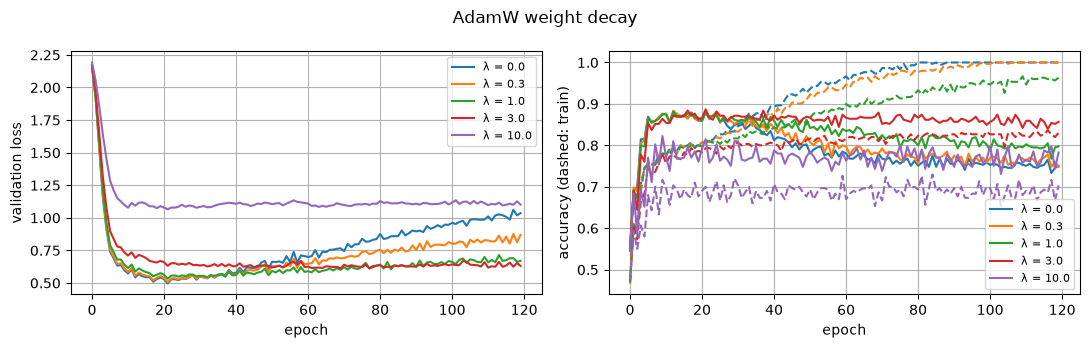

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i, wd in enumerate(wd_values):
    h = wd_results[wd][0]
    axes[0].plot(h["val_loss"], color=f"C{i}", label=f"λ = {wd}")
    axes[1].plot(h["train_acc"], color=f"C{i}", ls="--")
    axes[1].plot(h["val_acc"], color=f"C{i}", label=f"λ = {wd}")
axes[0].set_ylabel("validation loss"); axes[1].set_ylabel("accuracy (dashed: train)")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.suptitle("AdamW weight decay"); plt.tight_layout(); plt.show()

Moderate weight decay keeps the validation loss from blowing up and stops the
network from memorising every noisy label; too much decay underfits (training
accuracy stays low). As always, $\lambda$ is a hyper-parameter chosen on the
validation set.

## 4. Early stopping

The validation curve of the baseline suggests the simplest regulariser of all:
**stop training when the validation loss stops improving**, and keep the
parameters from the best epoch. In practice we wait for `patience` epochs
without improvement before stopping, to be robust to noise in the curve.

Early stopping is a genuine regulariser. For a quadratic loss and gradient
descent started at $\mathbf w_0=0$, one can show that after $t$ steps with
learning rate $\eta$ the solution resembles $L_2$ regularisation with
$\lambda \approx 1/(\eta t)$ (Goodfellow et al., §7.8): the number of steps
limits how far the weights can travel from the initialisation.

baseline: best val loss at epoch 22, val acc there 0.879 vs 0.751 at the end


stopped after 37 epochs, restored epoch 22; val acc 0.879


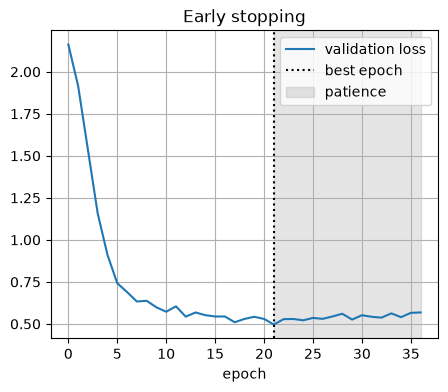

In [9]:
best_epoch = int(np.argmin(hist_base["val_loss"]))
print(f"baseline: best val loss at epoch {best_epoch + 1}, "
      f"val acc there {hist_base['val_acc'][best_epoch]:.3f} vs {hist_base['val_acc'][-1]:.3f} at the end")

def train_early_stopping(model, optimizer, train_ds, max_epochs=200, patience=15, seed=0):
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(train_ds, batch_size=32, shuffle=True, generator=g)
    best_loss, best_state, best_ep, waited, val_curve = float("inf"), None, 0, 0, []
    for epoch in range(max_epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        val_loss, _ = evaluate(model, val_loader)
        val_curve.append(val_loss)
        if val_loss < best_loss - 1e-4:
            best_loss, best_ep, waited = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())     # a real copy, not a reference!
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_state)
    return best_ep, val_curve

torch.manual_seed(0)
es_model = make_mlp()
best_ep, curve = train_early_stopping(es_model, torch.optim.Adam(es_model.parameters(), lr=1e-3), train_ds)
print(f"stopped after {len(curve)} epochs, restored epoch {best_ep + 1}; "
      f"val acc {evaluate(es_model, val_loader)[1]:.3f}")

plt.plot(curve, label="validation loss"); plt.axvline(best_ep, color="k", ls=":", label="best epoch")
plt.axvspan(best_ep, len(curve) - 1, color="gray", alpha=0.2, label="patience")
plt.xlabel("epoch"); plt.legend(); plt.title("Early stopping"); plt.show()

Note the `copy.deepcopy`: `model.state_dict()` returns references to the live
parameter tensors, which keep changing as training continues.

## 5. Dropout

**Dropout** (Srivastava et al., 2014) randomly sets each hidden activation to
zero with probability $p$ during training, using a fresh random mask for every
example and every forward pass. Each mini-batch therefore trains a different
"thinned" sub-network; the units cannot rely on specific other units being
present (they cannot *co-adapt*) and must learn redundant, robust features.

**Inverted dropout.** With a mask $m_i\sim\text{Bernoulli}(1-p)$ we compute

$$\tilde h_i = \frac{m_i\, h_i}{1-p}, \qquad \mathbb E[\tilde h_i] = h_i .$$

Rescaling during training keeps the expected activation unchanged, so at test
time we simply use the full network with no masking and no rescaling. This is
what `nn.Dropout(p)` does: random masking in `train()` mode, the identity in
`eval()` mode. (Forgetting `model.eval()` at test time is the classic dropout bug.)

**Ensemble view.** A network with $n$ droppable units implicitly contains $2^n$
sub-networks that share weights; dropout trains all of them, and the
deterministic test-time network approximates the (geometric) average of their
predictions — an ensemble at the price of one model.

In [10]:
drop = nn.Dropout(p=0.5)
h = torch.ones(2, 10)
drop.train()
print("train mode:\n", drop(h))
drop.eval()
print("eval mode:\n", drop(h))

drop.train()
big = drop(torch.ones(1000, 1000))
print(f"fraction zeroed {(big == 0).float().mean().item():.3f} | mean {big.mean().item():.3f} (≈ 1)")

train mode:
 tensor([[0., 0., 0., 0., 2., 2., 2., 2., 2., 0.],
        [0., 0., 0., 0., 0., 2., 2., 0., 2., 0.]])
eval mode:
 tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])
fraction zeroed 0.500 | mean 1.001 (≈ 1)


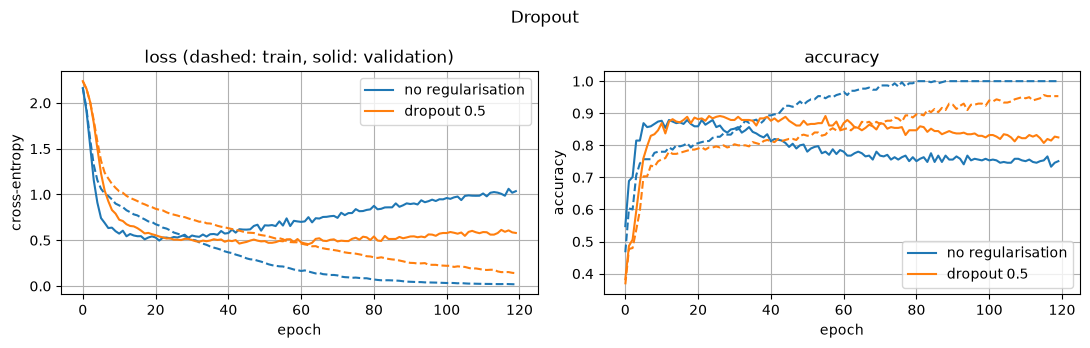

In [11]:
torch.manual_seed(0)
drop_model = make_mlp(dropout=0.5)
hist_drop = train_model(drop_model, torch.optim.Adam(drop_model.parameters(), lr=1e-3), train_ds)
plot_history({"no regularisation": hist_base, "dropout 0.5": hist_drop}, "Dropout")

With dropout the network memorises the noisy labels much more slowly and the
validation loss stays far lower. Dropout makes training noisier and slower;
typically we need more epochs, and $p\in[0.1, 0.5]$ for hidden layers.

### Monte Carlo dropout

Gal & Ghahramani (2016) showed that keeping dropout **on** at test time and
averaging $T$ stochastic forward passes,

$$p(y\mid\mathbf x) \approx \frac1T\sum_{t=1}^T \operatorname{softmax}\big(f_{\theta, m_t}(\mathbf x)\big),$$

can be interpreted as approximate Bayesian inference. The disagreement between
the passes is a cheap estimate of the model's **uncertainty**. Below we compare
the predictive entropy on validation examples the model gets right and wrong.

MC-dropout accuracy 0.832


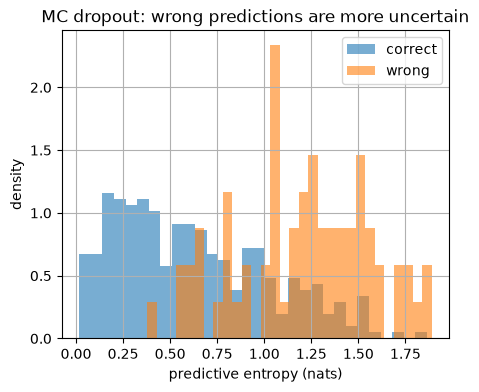

In [12]:
@torch.no_grad()
def mc_dropout_predict(model, X, T=50):
    model.train()                      # keep dropout active (careful: would also affect batch norm!)
    probs = torch.stack([torch.softmax(model(X), dim=1) for _ in range(T)])   # (T, N, K)
    model.eval()
    return probs.mean(0)

torch.manual_seed(0)
Xv = torch.from_numpy(X_val).to(device)
p_mc = mc_dropout_predict(drop_model, Xv).cpu()
entropy = -(p_mc * torch.log(p_mc + 1e-12)).sum(1).numpy()
correct = (p_mc.argmax(1).numpy() == y_val)
print(f"MC-dropout accuracy {correct.mean():.3f}")
plt.hist(entropy[correct], bins=30, alpha=0.6, density=True, label="correct")
plt.hist(entropy[~correct], bins=30, alpha=0.6, density=True, label="wrong")
plt.xlabel("predictive entropy (nats)"); plt.ylabel("density"); plt.legend()
plt.title("MC dropout: wrong predictions are more uncertain"); plt.show()

## 6. Batch normalisation

**Batch normalisation** (Ioffe & Szegedy, 2015) normalises every feature of a
layer's pre-activation over the mini-batch $\mathcal B = \{\mathbf z_1,\dots,\mathbf z_B\}$
and then applies a learnable affine map:

$$\mu_j = \frac1B\sum_{i} z_{ij}, \quad
\sigma_j^2 = \frac1B\sum_i (z_{ij}-\mu_j)^2, \quad
\hat z_{ij} = \frac{z_{ij}-\mu_j}{\sqrt{\sigma_j^2+\epsilon}}, \quad
y_{ij} = \gamma_j \hat z_{ij} + \beta_j .$$

The learnable $\gamma, \beta$ make sure the layer can still represent any
scale and offset (including the identity). Batch norm is differentiated
*through* the batch statistics: the gradient for one example depends on the
others in the batch.

**Train versus eval.** At test time we may predict a single example, so batch
statistics are unavailable — and we want deterministic predictions anyway.
During training, `nn.BatchNorm1d` keeps exponential moving averages

$$\mu^{\text{run}} \leftarrow (1-\alpha)\,\mu^{\text{run}} + \alpha\,\mu_{\mathcal B}, \qquad
\sigma^{2,\text{run}} \leftarrow (1-\alpha)\,\sigma^{2,\text{run}} + \alpha\,\tfrac{B}{B-1}\sigma^2_{\mathcal B}$$

with `momentum` $\alpha = 0.1$ (beware: the opposite convention to optimiser
momentum), stored as **buffers** in the `state_dict`. In `eval()` mode these
running statistics are used instead of the batch statistics.

In [13]:
torch.manual_seed(0)
bn = nn.BatchNorm1d(3)
print("buffers:", [name for name, _ in bn.named_buffers()])
z = 5 + 2 * torch.randn(64, 3)
bn.train()
out = bn(z)
print("train mode: batch mean", out.mean(0).detach().numpy().round(3), "std", out.std(0, correction=0).detach().numpy().round(3))
print("running mean after one batch:", bn.running_mean.numpy().round(3), "(= 0.9·0 + 0.1·batch mean)")

for _ in range(100):
    bn(5 + 2 * torch.randn(64, 3))
print("running mean / var after 100 batches:", bn.running_mean.numpy().round(2), bn.running_var.numpy().round(2))

bn.eval()
x1 = z[:1]
print("eval mode, single example:", bn(x1).detach().numpy().round(3),
      "| manual:", ((x1 - bn.running_mean) / torch.sqrt(bn.running_var + bn.eps)).numpy().round(3))

buffers: ['running_mean', 'running_var', 'num_batches_tracked']
train mode: batch mean [-0. -0. -0.] std [1. 1. 1.]
running mean after one batch: [0.504 0.45  0.554] (= 0.9·0 + 0.1·batch mean)
running mean / var after 100 batches: [5.02 4.96 4.91] [4.04 4.13 4.02]
eval mode, single example: [[-1.128 -1.113 -0.204]] | manual: [[-1.128 -1.113 -0.204]]


**Why does it help?** The original motivation was to reduce "internal covariate
shift" — the change in the distribution of a layer's inputs as earlier layers
are updated. Later work (Santurkar et al., 2018) argued that the main benefit is
a smoother loss landscape, which allows much larger learning rates. Either way,
the practical effects are:

* much faster and more robust training of deep networks, less sensitivity to
  initialisation and learning rate;
* a mild regularising effect, because the batch statistics inject noise that
  depends on the random composition of the mini-batch.

Let us train a deliberately deep and narrow MLP (10 hidden layers of width 64)
with plain SGD, with and without batch norm (placed between the linear layer
and the ReLU, as in the original paper). PyTorch's default initialisation of
`nn.Linear` draws weights from $U(-1/\sqrt{d_{in}}, 1/\sqrt{d_{in}})$, i.e. a variance
of $1/(3d_{in})$ — a factor 6 below the He initialisation of Lecture 3 — so the
signal shrinks layer after layer and the plain network learns very slowly.
Batch norm re-scales every layer and removes the problem.

plain     : final val acc 0.101


batch norm: final val acc 0.926


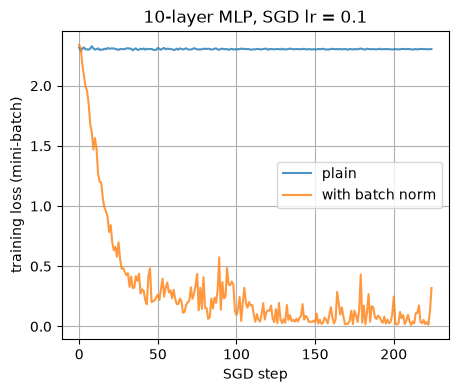

In [14]:
def deep_mlp(depth=10, width=64, batchnorm=False):
    layers, d = [], 64
    for _ in range(depth):
        layers.append(nn.Linear(d, width))
        if batchnorm:
            layers.append(nn.BatchNorm1d(width))
        layers.append(nn.ReLU())
        d = width
    layers.append(nn.Linear(d, 10))
    return nn.Sequential(*layers).to(device)

full_train_ds = to_t(X_rest, y_rest)          # the full, clean training pool
bn_hists = {}
for use_bn in (False, True):
    torch.manual_seed(0)
    m = deep_mlp(batchnorm=use_bn)
    opt = torch.optim.SGD(m.parameters(), lr=0.1)
    g = torch.Generator().manual_seed(0)
    loader = DataLoader(full_train_ds, batch_size=64, shuffle=True, generator=g)
    losses = []
    for epoch in range(15):
        m.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(m(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
    bn_hists["with batch norm" if use_bn else "plain"] = losses
    print(f"{'batch norm' if use_bn else 'plain':10s}: final val acc {evaluate(m, val_loader)[1]:.3f}")

for name, losses in bn_hists.items():
    plt.plot(losses, label=name, alpha=0.8)
plt.xlabel("SGD step"); plt.ylabel("training loss (mini-batch)"); plt.legend()
plt.title("10-layer MLP, SGD lr = 0.1"); plt.show()

**Caveats of batch norm.** It behaves badly with very small batches (noisy
statistics), couples the examples in a batch, makes training and test behaviour
differ, and is awkward for sequences of varying length.

**Layer normalisation** (Ba et al., 2016) normalises over the *features* of each
example instead of over the batch:

$$\mu_i = \frac1D\sum_j z_{ij}, \quad \sigma_i^2 = \frac1D\sum_j (z_{ij}-\mu_i)^2, \quad
y_{ij} = \gamma_j \frac{z_{ij}-\mu_i}{\sqrt{\sigma_i^2+\epsilon}} + \beta_j .$$

It has no running statistics, behaves identically in training and evaluation
and works for any batch size — which is why it is the normalisation of choice in
RNNs and Transformers (Lecture 8). Batch norm remains standard in CNNs (Lecture 6).

In [15]:
z = torch.randn(4, 6)
ln = nn.LayerNorm(6)
manual = (z - z.mean(1, keepdim=True)) / torch.sqrt(z.var(1, correction=0, keepdim=True) + ln.eps)
print("LayerNorm matches manual per-example normalisation:", torch.allclose(ln(z), manual, atol=1e-5))

LayerNorm matches manual per-example normalisation: True


## 7. Data augmentation

The best regulariser is more data. When we cannot collect more, we can often
create plausible new examples by applying transformations under which the label
is **invariant**. For images: small translations, rotations, crops, scaling,
colour jitter, noise. The transformations must respect the task — a horizontal
flip is fine for cats but turns a "2" into something that is not a digit, and a
180° rotation turns a 6 into a 9.

Augmentation is applied on the fly, with fresh random transformations every
epoch, so the network never sees exactly the same input twice. The natural place
for it is the `Dataset.__getitem__`. For our $8\times8$ digits we use random
shifts of up to one pixel (pad with zeros, then crop) plus a little Gaussian noise.

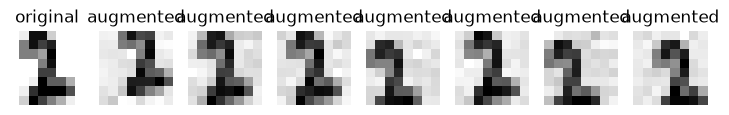

In [16]:
class AugmentedDigits(Dataset):
    def __init__(self, X, y, max_shift=1, noise=0.05):
        self.X = torch.as_tensor(X, dtype=torch.float32).reshape(-1, 8, 8)
        self.y = torch.as_tensor(y, dtype=torch.long)
        self.max_shift, self.noise = max_shift, noise

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        s = self.max_shift
        img = F.pad(self.X[idx], (s, s, s, s))                  # (8+2s, 8+2s)
        dy, dx = torch.randint(0, 2 * s + 1, (2,)).tolist()     # random crop offset
        img = img[dy:dy + 8, dx:dx + 8]
        img = img + self.noise * torch.randn_like(img)
        return img.reshape(64), self.y[idx]

aug_ds = AugmentedDigits(X_small, y_small)
torch.manual_seed(0)
fig, axes = plt.subplots(1, 8, figsize=(9, 1.4))
axes[0].imshow(X_small[0].reshape(8, 8), cmap="gray_r"); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(aug_ds[0][0].reshape(8, 8).numpy(), cmap="gray_r"); ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.show()

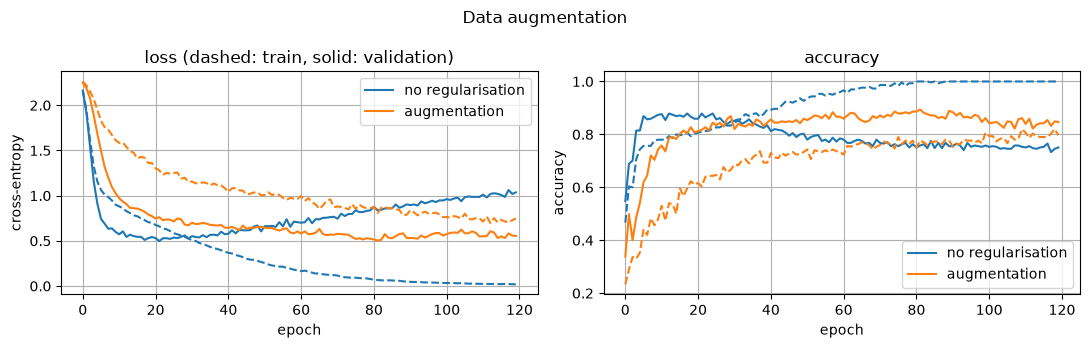

In [17]:
torch.manual_seed(0)
aug_model = make_mlp()
hist_aug = train_model(aug_model, torch.optim.Adam(aug_model.parameters(), lr=1e-3), aug_ds)
plot_history({"no regularisation": hist_base, "augmentation": hist_aug}, "Data augmentation")

Because the network must now fit a whole *cloud* of shifted, noisy versions of
every training image, memorising the 50 or so wrong labels becomes much harder.

## 8. Putting it together

Regularisers can be combined. Here we train with dropout, weight decay *and*
augmentation, and compare all models on the **test** set (each evaluated once,
with the parameters at the end of training — except the early-stopping model).

none            test accuracy 0.742
weight decay    test accuracy 0.878
early stopping  test accuracy 0.882
dropout         test accuracy 0.827
augmentation    test accuracy 0.864
combined        test accuracy 0.842


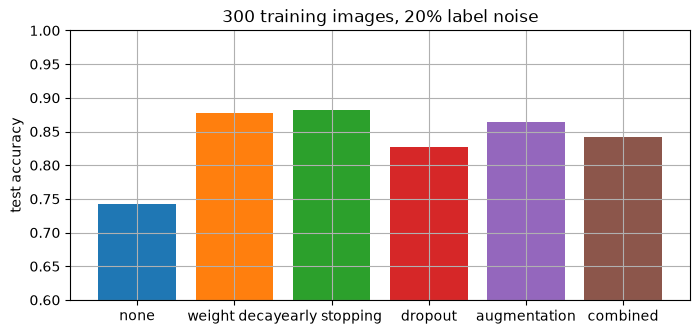

In [18]:
torch.manual_seed(0)
combo = make_mlp(dropout=0.3)
hist_combo = train_model(combo, adamw_no_bias_decay(combo, weight_decay=1.0), aug_ds)

wd_model = wd_results[3.0][2]          # trained in Section 3

models = {
    "none": baseline,
    "weight decay": wd_model,
    "early stopping": es_model,
    "dropout": drop_model,
    "augmentation": aug_model,
    "combined": combo,
}
test_accs = {name: evaluate(m, test_loader)[1] for name, m in models.items()}
for name, acc in test_accs.items():
    print(f"{name:15s} test accuracy {acc:.3f}")

plt.figure(figsize=(8, 3.5))
plt.bar(list(test_accs), list(test_accs.values()), color=[f"C{i}" for i in range(len(test_accs))])
plt.ylim(0.6, 1.0); plt.ylabel("test accuracy"); plt.title("300 training images, 20% label noise")
plt.show()

## 9. A modern twist: double descent

The bias–variance picture predicts a U-shaped test error as capacity grows. Yet
huge, over-parameterised networks that fit their training data perfectly often
generalise *well*. Belkin et al. (2019) reconciled the two with the **double
descent** curve: the test error follows the classical U up to the
**interpolation threshold**, where the model has just enough capacity to fit the
training data exactly, peaks there, and then *decreases again* as capacity keeps
growing.

A minimal reproduction: random ReLU features $\phi(\mathbf x)=\operatorname{ReLU}(V\mathbf x)$
with a fixed random $V\in\mathbb R^{p\times 64}$, and a linear least-squares readout
trained on $n=100$ digits. For $p>n$ there are infinitely many interpolating
solutions; the pseudo-inverse picks the one with **minimum norm** — an implicit
regulariser, similar to what gradient descent from a small initialisation does.

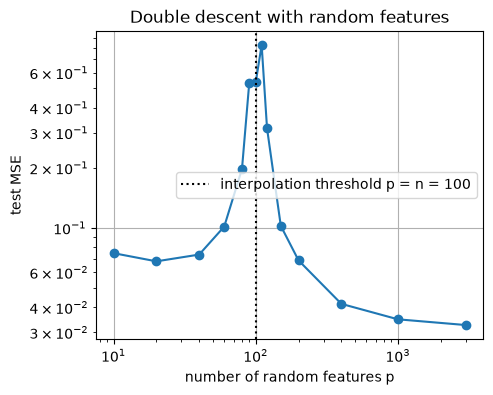

In [19]:
idx = rng.permutation(len(X_pool))
n_dd = 100
Xa, ya = X_pool[idx[:n_dd]].astype(np.float64), y_pool[idx[:n_dd]]
Xb, yb_dd = X_pool[idx[n_dd:]].astype(np.float64), y_pool[idx[n_dd:]]
Ya, Yb = np.eye(10)[ya], np.eye(10)[yb_dd]

widths = [10, 20, 40, 60, 80, 90, 100, 110, 120, 150, 200, 400, 1000, 3000]
dd_err = []
for p in widths:
    errs = []
    for s in range(5):
        V = np.random.default_rng(s).standard_normal((64, p)) / 8.0
        Pa, Pb = np.maximum(Xa @ V, 0), np.maximum(Xb @ V, 0)
        W = np.linalg.pinv(Pa) @ Ya                     # minimum-norm least squares
        errs.append(np.mean((Pb @ W - Yb) ** 2))
    dd_err.append(np.median(errs))

plt.semilogy(widths, dd_err, "o-")
plt.axvline(n_dd, color="k", ls=":", label=f"interpolation threshold p = n = {n_dd}")
plt.xscale("log"); plt.xlabel("number of random features p"); plt.ylabel("test MSE")
plt.legend(); plt.title("Double descent with random features"); plt.show()

At $p\approx n$ the system is square: there is exactly one interpolating
solution and it is extremely sensitive to the noise in the data (the smallest
singular values of the feature matrix are close to zero), so the variance
explodes. Beyond the threshold, the minimum-norm solution among many
interpolants becomes smoother as $p$ grows. Double descent also appears as a
function of training *epochs* and of *dataset size*, and it is strongest when
labels are noisy. Explicit regularisation (e.g. ridge with a well-tuned
$\lambda$) largely removes the peak.

## Summary

| Technique | What it does | PyTorch |
|---|---|---|
| Weight decay | shrinks weights, prefers smooth functions | `weight_decay=` in the optimiser; `AdamW` for adaptive methods |
| Early stopping | limits the number of steps; keep the best validation checkpoint | a loop + `copy.deepcopy(model.state_dict())` |
| Dropout | trains an implicit ensemble of thinned networks | `nn.Dropout(p)`; differs in `train()` / `eval()` |
| Batch norm | normalises with batch statistics; faster, more stable training | `nn.BatchNorm1d/2d`; running stats used in `eval()` |
| Layer norm | normalises each example over its features | `nn.LayerNorm(d)` |
| Data augmentation | label-preserving transformations enlarge the dataset | random transforms in `Dataset.__getitem__` |

Practical recipe: start with a model large enough to overfit, then add
regularisation (augmentation and weight decay first, dropout where it helps),
monitor validation curves, and keep the best checkpoint.

**Further reading.**
Goodfellow, Bengio & Courville, *Deep Learning*, ch. 7 (Regularization) and §8.7.1 (batch norm);
Srivastava et al., *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*, JMLR 2014;
Ioffe & Szegedy, *Batch Normalization*, ICML 2015; Ba, Kiros & Hinton, *Layer Normalization*, 2016;
Loshchilov & Hutter, *Decoupled Weight Decay Regularization*, ICLR 2019;
Gal & Ghahramani, *Dropout as a Bayesian Approximation*, ICML 2016;
Zhang et al., *Understanding Deep Learning Requires Rethinking Generalization*, ICLR 2017;
Belkin et al., *Reconciling Modern Machine-Learning Practice and the Classical Bias–Variance Trade-off*, PNAS 2019;
Nakkiran et al., *Deep Double Descent*, ICLR 2020.